In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression


In [2]:

# Load the dataset
print(" Loading Dataset ")
try:
    df = pd.read_csv('cleaned_Dataset.csv')
except FileNotFoundError:
    df = pd.read_csv('Dataset.csv')


 Loading Dataset 


In [3]:

print("\n Step 1: Preparing Release-Year Data ")

yearly_counts = df.groupby('release_year').size().reset_index(name='content_count')


recent_trends = yearly_counts[yearly_counts['release_year'] >= 2000].copy()
print(recent_trends.tail())




 Step 1: Preparing Release-Year Data 
    release_year  content_count
69          2017           1030
70          2018           1146
71          2019           1030
72          2020            953
73          2021            592


In [4]:

print("\n Step 2 & 3: Building the Forecasting Model ")

X = recent_trends[['release_year']].values
y = recent_trends['content_count'].values


model = LinearRegression()
model.fit(X, y)


future_years = np.array([[2022], [2023], [2024], [2025], [2026]])
future_predictions = model.predict(future_years)

print("\nPredictions for next 5 years:")
for yr, pred in zip(future_years.flatten(), future_predictions):
    print(f"Year {yr}: {int(pred)} titles predicted")




 Step 2 & 3: Building the Forecasting Model 

Predictions for next 5 years:
Year 2022: 962 titles predicted
Year 2023: 1013 titles predicted
Year 2024: 1064 titles predicted
Year 2025: 1116 titles predicted
Year 2026: 1167 titles predicted



 Step 4: Visualizing Future Predictions 


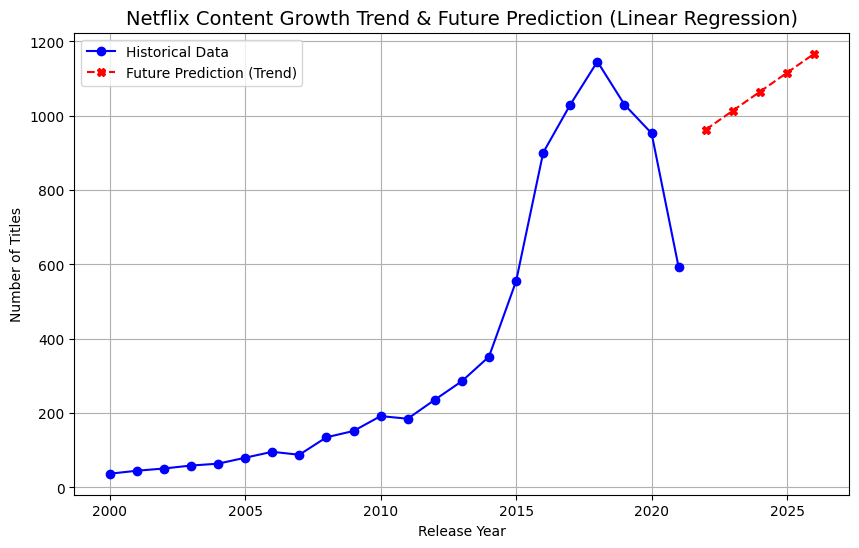

In [5]:

print("\n Step 4: Visualizing Future Predictions ")
plt.figure(figsize=(10, 6))


plt.plot(recent_trends['release_year'], recent_trends['content_count'], label='Historical Data', marker='o', color='blue')


plt.plot(future_years, future_predictions, label='Future Prediction (Trend)', linestyle='--', marker='X', color='red')

plt.title('Netflix Content Growth Trend & Future Prediction (Linear Regression)', fontsize=14)
plt.xlabel('Release Year')
plt.ylabel('Number of Titles')
plt.legend()
plt.grid(True)
plt.show()